<a href="https://colab.research.google.com/github/SergeevaAI/Data-acquisition-consolidation-and-analytics-software/blob/main/lr_2/%D0%9B%D0%912_%D0%9A%D0%BE%D0%BD%D1%81%D0%BE%D0%BB%D0%B8%D0%B4%D0%B0%D1%86%D0%B8%D1%8F_CSV_Excel_JSON_SQLite_%D1%81%D1%82%D1%83%D0%B4%D0%B5%D0%BD%D1%82.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 100 баллов

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. Выгрузить витрину в BigQuery и повторить расчёт там (пошаговая инструкция ниже).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [ ]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 26                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = True      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [ ]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 26 — Промышленное производство
Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести
аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»

CSV  : Заводы        (справочник субъектов)
XLSX : Партии продукции          (события, объём в единицах: тонн)
JSON : Отпускные цены          (цены, разрез: марка продукции)

Объём генерации: субъектов 9, событий 4 000, уровень дефектов ★★★
Аналитическая задача: Вклад марок продукции и сезонность отгрузок


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [ ]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       10   размер:      0.7 КБ
events.xlsx     строк:    4 026   размер:    148.7 КБ
prices.json     строк:    8 024   размер:   1069.8 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [ ]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Постройте профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений. Верните DataFrame."""
    rows = []
    for col in df.columns:
        s = df[col]
        filled = s.notna() & (s.astype(str).str.strip() != "")
        examples = s[filled].astype(str).head(2).tolist()
        rows.append({
            "источник": name,
            "колонка": col,
            "тип": str(s.dtype),
            "заполнено, %": round(float(filled.mean()) * 100, 1),
            "уникальных": int(s.nunique(dropna=True)),
            "пример": " | ".join(examples)[:42],
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
# Заполните журнал проблем качества по шести измерениям. Для каждой найденной проблемы —
# строка с полями: измерение, источник, проблема, число строк, решение.
#   Полнота        — пропуски по колонкам
#   Уникальность   — полные дубликаты и повторы ключей (entity_id, event_id, price_id)
#   Согласованность— два формата даты, числа строками с валютой и пробелами
#   Валидность     — отрицательные цены, нулевой объём
#   Целостность    — записи с внешним ключом, которого нет в справочнике (в обе стороны)
#   Точность       — выбросы цен по правилу 3×IQR
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})
def as_number(s):
    # только чтобы поймать минус и ноль, это ещё не очистка
    t = (s.astype(str)
         .str.replace(r"[^\d,.\-]", "", regex=True)
         .str.replace(" ", "", regex=False)
         .str.replace(",", ".", regex=False))
    return pd.to_numeric(t, errors="coerce")

# 1) полнота
for name, df in SOURCES.items():
    for col in df.columns:
        n_miss = int(df[col].isna().sum() + (df[col].astype(str).str.strip() == "").sum())
        if n_miss > 0:
            add_issue("Полнота", name, "пропуски в «" + col + "»", n_miss,
                      "NaN не заменять нулём, строку не терять")

# 2) уникальность
n_dup_e = int(raw_entities.duplicated().sum())
if n_dup_e:
    add_issue("Уникальность", "CSV", "полные дубли заводов", n_dup_e, "оставить одну строку")

n_dup_ev = int(raw_events["event_id"].duplicated().sum())
if n_dup_ev:
    add_issue("Уникальность", "XLSX", "повтор event_id", n_dup_ev, "keep='first'")

n_dup_p = int(raw_prices["price_id"].duplicated().sum())
if n_dup_p:
    add_issue("Уникальность", "JSON", "повтор price_id", n_dup_p, "keep='first'")

# 3) согласованность
n_dot_dates = int(raw_events["event_date"].astype(str).str.match(r"\d{2}\.\d{2}\.\d{4}").sum())
if n_dot_dates:
    add_issue("Согласованность", "XLSX", "дата как дд.мм.гггг", n_dot_dates, "разобрать оба формата в datetime")

n_rub = int(raw_prices["unit_price"].astype(str).str.contains("₽").sum())
if n_rub:
    add_issue("Согласованность", "JSON", "цена строкой с валютой", n_rub, "regex-очистка и приведение к float")

# 4) валидность
n_neg = int((as_number(raw_prices["unit_price"]) < 0).sum())
if n_neg:
    add_issue("Валидность", "JSON", "отрицательная цена", n_neg, "исключить из расчёта")

n_bad_vol = int((as_number(raw_events["volume_units"]) <= 0).sum())
if n_bad_vol:
    add_issue("Валидность", "XLSX", "нулевой или отрицательный объём", n_bad_vol, "в расчёт не брать")

# 5) целостность
known_ids = set(raw_entities["entity_id"])
n_orphan = int((~raw_events["entity_id"].isin(known_ids)).sum())
if n_orphan:
    add_issue("Целостность", "XLSX", "партия на несуществующий завод", n_orphan, "вынести в карантин, не включать")

n_price_lost = int((~raw_prices["event_id"].isin(set(raw_events["event_id"]))).sum())
if n_price_lost:
    add_issue("Целостность", "JSON", "цена без партии", n_price_lost, "карантин")

# 6) точность: выбросы по правилу межквартильного размаха
p = as_number(raw_prices["unit_price"]).dropna()
q1, q3 = p.quantile(0.25), p.quantile(0.75)
iqr = q3 - q1
n_out = int(((p < q1 - 3 * iqr) | (p > q3 + 3 * iqr)).sum())
if n_out:
    add_issue("Точность", "JSON", "выброс цены по правилу межквартильного размаха", n_out,
              "проверить вручную, пометить")


issues_df=pd.DataFrame(issues)
display(issues_df)
print("проблем в журнале:", len(issues))

,источник,колонка,тип,"заполнено, %",уникальных,пример
0,CSV · Заводы,entity_id,object,100.00,9,E001 | E002
1,CSV · Заводы,entity_name,object,100.00,9,Заводы «Самара» | Заводы «Екатеринбург»
2,CSV · Заводы,region,object,90.00,8,Самара | Екатеринбург
3,CSV · Заводы,founded_year,object,100.00,7,2015 | 1991
4,XLSX · Партии продукции,event_id,object,100.00,4000,EV000001 | EV000002
5,XLSX · Партии продукции,entity_id,object,100.00,10,E002 | E001
6,XLSX · Партии продукции,event_date,object,100.00,378,2025-11-01 | 2025-06-28
7,XLSX · Партии продукции,route,object,100.00,144,Екатеринбург — Пермь | Самара — Ростов-на-
8,XLSX · Партии продукции,volume_units,object,99.70,383,305 | 240
9,XLSX · Партии продукции,asset_type,object,100.00,4,Тип A | Тип D


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Заводы,пропуски в «region»,1,"NaN не заменять нулём, строку не терять"
1,Полнота,XLSX · Партии продукции,пропуски в «volume_units»,13,"NaN не заменять нулём, строку не терять"
2,Полнота,JSON · Отпускные цены,пропуски в «unit_price»,17,"NaN не заменять нулём, строку не терять"
3,Уникальность,CSV,полные дубли заводов,1,оставить одну строку
4,Уникальность,XLSX,повтор event_id,26,keep='first'
5,Уникальность,JSON,повтор price_id,39,keep='first'
6,Согласованность,XLSX,дата как дд.мм.гггг,13,разобрать оба формата в datetime
7,Согласованность,JSON,цена строкой с валютой,17,regex-очистка и приведение к float
8,Валидность,JSON,отрицательная цена,19,исключить из расчёта
9,Целостность,XLSX,партия на несуществующий завод,20,"вынести в карантин, не включать"


проблем в журнале: 10


In [ ]:
# ------------------------------------------------------------------ TODO 3.3
# Определите кардинальность связей entities → events и events → prices: среднее и максимальное
# число потомков. Ответьте письменно: что произойдёт с суммой выручки при наивном JOIN трёх таблиц?
# сколько партий на один завод и сколько цен на одну партию
child_events = raw_events.groupby("entity_id").size()
child_prices = raw_prices.groupby("event_id").size()

card = pd.DataFrame({
    "связь": ["заводы → партии", "партии → цены"],
    "тип": ["1 : N", "1 : N"],
    "в среднем": [round(float(child_events.mean()), 2),
                  round(float(child_prices.mean()), 2)],
    "максимум": [int(child_events.max()), int(child_prices.max())],
})
print("\nКАРДИНАЛЬНОСТЬ СВЯЗЕЙ")
display(card)
dq_score = round(100 * (1 - issues_df["строк"].sum() / max(sum(len(d) for d in SOURCES.values()), 1)), 1)
print(f"\nИнтегральная оценка качества: {dq_score} % "
      f"(доля строк без зафиксированных проблем; показатель ориентировочный)")
print(f"На одно событие приходится в среднем {child_prices.mean():.2f} строк цен")
print("Cумма тонн и выручка завысятся примерно в", round(float(child_prices.mean()), 2), "раза")


КАРДИНАЛЬНОСТЬ СВЯЗЕЙ


,связь,тип,в среднем,максимум
0,заводы → партии,1 : N,402.60,756
1,партии → цены,1 : N,2.01,4



Интегральная оценка качества: 98.6 % (доля строк без зафиксированных проблем; показатель ориентировочный)
На одно событие приходится в среднем 2.01 строк цен
Cумма тонн и выручка завысятся примерно в 2.01 раза


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [ ]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    """Подсказка: убрать всё, кроме цифр, запятой, точки и минуса; решить, чем является запятая —
    десятичным разделителем или разделителем разрядов; затем pd.to_numeric(errors="coerce")."""
    s = series.astype(str)
    s = s.str.replace("\u00a0", " ", regex=False) # неразрывный пробел
    s = s.str.replace(r"[^\d,.\-]", "", regex=True) # выкинуть ₽ и буквы
    s = s.str.replace(" ", "", regex=False)
    both = s.str.contains(",") & s.str.contains(r"\.")
    s = np.where(both, s.str.replace(",", "", regex=False),
                 s.str.replace(",", ".", regex=False))
    return pd.to_numeric(pd.Series(s, index=series.index), errors="coerce")

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Разберите оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    a = pd.to_datetime(series, format="%Y-%m-%d", errors="coerce")
    b = pd.to_datetime(series, format="%d.%m.%Y", errors="coerce")
    return a.fillna(b)

# ------------------------------------------------------------------ TODO 4.3
# Очистите три набора и заполните журнал через log_step(). Правила:
#   * дубликаты удаляются по ключу (entity_id, event_id, price_id), остаётся первая запись;
#   * имена субъектов приводятся к единому виду (лишние пробелы, регистр);
#   * строки с нарушенной ссылочной целостностью и непригодными значениями уходят
#     в переменные quarantine_fk и quarantine_price, а не удаляются молча;
#   * пропуск остаётся пропуском: не заменяйте его нулём.
# На выходе должны быть: entities, events_valid, prices_valid, quarantine_fk, quarantine_price.
# заводы
n0 = len(raw_entities)
entities = raw_entities.drop_duplicates().copy()
entities["entity_name"] = (entities["entity_name"].str.strip()
                           .str.replace(r"\s+", " ", regex=True)
                           .str.title())
entities["founded_year"] = pd.to_numeric(entities["founded_year"], errors="coerce").astype("Int64")
entities = entities.drop_duplicates(subset=["entity_id"], keep="first")
log_step("заводы: дубли и имена", n0, len(entities), "пробелы/регистр, один entity_id")

# партии
n0 = len(raw_events)
events = raw_events.drop_duplicates(subset=["event_id"], keep="first").copy()
log_step("партии: дубли ключа", n0, len(events), "keep first")

events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])

n0 = len(events)
quarantine_fk = events[~events["entity_id"].isin(set(entities["entity_id"]))].copy()
events = events[events["entity_id"].isin(set(entities["entity_id"]))]
log_step("партии: чужой завод", n0, len(events),
         "в карантин " + str(len(quarantine_fk)))

n0 = len(events)
events_valid = events[(events["volume_units"].notna()) & (events["volume_units"] > 0)].copy()
log_step("партии: плохой объём", n0, len(events_valid), "NaN и отрицательные, нулевые не в выручку")

# цены
n0 = len(raw_prices)
prices = raw_prices.drop_duplicates(subset=["price_id"], keep="first").copy()
log_step("цены: дубли ключа", n0, len(prices), "keep first")
prices["unit_price"] = to_number(prices["unit_price"])

n0 = len(prices)
quarantine_price = prices[(prices["unit_price"].isna()) | (prices["unit_price"] <= 0)].copy()
prices_valid = prices[(prices["unit_price"].notna()) & (prices["unit_price"] > 0)].copy()
log_step("цены: пропуск/минус", n0, len(prices_valid),
         "карантин " + str(len(quarantine_price)))

n0 = len(prices_valid)
prices_valid = prices_valid[prices_valid["event_id"].isin(set(events_valid["event_id"]))]
log_step("цены: нет партии", n0, len(prices_valid), "оставлены связанные")

display(pd.DataFrame(CLEAN_LOG))
print("карантин FK", len(quarantine_fk), "карантин цен", len(quarantine_price))

,шаг,было строк,стало строк,изменено,комментарий
0,заводы: дубли и имена,10,9,1,"пробелы/регистр, один entity_id"
1,партии: дубли ключа,4026,4000,26,keep first
2,партии: чужой завод,4000,3980,20,в карантин 20
3,партии: плохой объём,3980,3967,13,"NaN и отрицательные, нулевые не в выручку"
4,цены: дубли ключа,8024,7985,39,keep first
5,цены: пропуск/минус,7985,7949,36,карантин 36
6,цены: нет партии,7949,7879,70,оставлены связанные


карантин FK 20 карантин цен 36


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [ ]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
# Создайте схему: три таблицы с первичными ключами, внешними ключами и ограничениями
# CHECK (volume_units > 0, unit_price > 0), а также индексы по внешним ключам и дате.
conn.executescript("""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,
    founded_year INTEGER
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id),
    event_date   TEXT NOT NULL,
    route        TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type   TEXT
);
CREATE TABLE prices (
    price_id    TEXT PRIMARY KEY,
    event_id    TEXT NOT NULL REFERENCES events(event_id),
    unit_price  REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
""")

In [ ]:
# ------------------------------------------------------------------ TODO 5.2
# Загрузите очищенные данные (entities, events_valid, prices_valid) через to_sql
# и выведите число строк в каждой таблице запросом к базе, а не из DataFrame.
entities.to_sql("entities", conn, if_exists="append", index=False)

events_out = events_valid.copy()
# в SQLite даты лучше строкой ГГГГ-ММ-ДД, так сортируются
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")
events_out[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]].to_sql(
    "events", conn, if_exists="append", index=False)

prices_valid[["price_id", "event_id", "unit_price", "price_class"]].to_sql(
    "prices", conn, if_exists="append", index=False)
conn.commit()

counts = pd.read_sql("""
SELECT 'entities' AS t, COUNT(*) AS n FROM entities
UNION ALL SELECT 'events', COUNT(*) FROM events
UNION ALL SELECT 'prices', COUNT(*) FROM prices
""", conn)
display(counts)

,t,n
0,entities,9
1,events,3967
2,prices,7879


In [ ]:
# ------------------------------------------------------------------ TODO 5.3
# Напишите ДВА запроса:
#   naive_sql   — «в лоб»: entities JOIN events JOIN prices, SUM(volume_units * unit_price);
#   correct_sql — корректный: сначала CTE со свёрткой цен до одной строки на событие
#                 (AVG(unit_price) GROUP BY event_id), затем соединение с объёмом.
# Сравните результаты по каждому субъекту, посчитайте коэффициент завышения
# и письменно объясните, откуда он берётся.
naive_sql = """
SELECT e.entity_id, e.entity_name,
       SUM(ev.volume_units * p.unit_price) AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
naive = pd.read_sql(naive_sql, conn)

correct_sql = """
WITH price_per_event AS (
    SELECT event_id, AVG(unit_price) AS avg_price
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id, e.entity_name, e.region,
       COUNT(ev.event_id) AS events_cnt,
       SUM(ev.volume_units) AS volume_total,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
revenue_sql = pd.read_sql(correct_sql, conn)

cmp = revenue_sql.merge(naive, on=["entity_id", "entity_name"])
cmp["завышение"] = (cmp["revenue_naive"] / cmp["revenue"]).round(2)
display(cmp)
overstate = float(cmp["revenue_naive"].sum() / cmp["revenue"].sum())
print("наивный JOIN завышает выручку в", round(overstate, 2), "раза")

,entity_id,entity_name,region,events_cnt,volume_total,revenue,revenue_naive,завышение
0,E001,Заводы «Самара»,Самара,745,"156,985.00","2,628,364,674.45","5,207,879,621.45",1.98
1,E002,Заводы «Екатеринбург»,Екатеринбург,611,"124,968.00","2,183,811,415.68","4,334,389,024.12",1.98
2,E003,Заводы «Санкт-Петербург»,Санкт-Петербург,601,"124,032.00","2,082,551,558.22","4,160,947,214.36",2.00
3,E004,Заводы «Ростов-На-Дону»,None,474,"97,564.00","1,665,168,229.41","3,236,800,526.68",1.94
4,E005,Заводы «Краснодар»,Краснодар,433,"88,445.00","1,473,149,403.48","2,966,828,937.98",2.01
5,E006,Заводы «Омск»,Омск,387,"79,899.00","1,316,078,985.07","2,683,826,370.20",2.04
6,E007,Заводы «Уфа»,Уфа,305,"61,462.00","1,071,134,918.57","2,078,193,408.51",1.94
7,E008,Заводы «Казань»,Казань,231,"50,443.00","849,893,217.31","1,783,029,511.55",2.10
8,E009,Заводы «Новосибирск»,Новосибирск,173,"37,395.00","601,299,785.40","1,171,892,503.85",1.95


наивный JOIN завышает выручку в 1.99 раза


In [ ]:
# ------------------------------------------------------------------ TODO 5.4
# Повторите корректный расчёт средствами pandas и сверьте с SQL: расхождение
# должно быть на уровне округления. Результаты: revenue_sql, revenue_pd, consolidated.
avg_price = prices_valid.groupby("event_id", as_index=False)["unit_price"].mean()
consolidated = (events_valid
                .merge(avg_price, on="event_id")
                .merge(entities, on="entity_id"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["unit_price"]

revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"),
                   volume_total=("volume_units", "sum"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False))

delta = float((revenue_sql.set_index("entity_id")["revenue"]
               - revenue_pd.set_index("entity_id")["revenue"]).abs().max())
print("макс. расхождение SQL и pandas, ₽:", delta)
display(revenue_sql.head())

макс. расхождение SQL и pandas, ₽: 0.003333449363708496


,entity_id,entity_name,region,events_cnt,volume_total,revenue
0,E001,Заводы «Самара»,Самара,745,"156,985.00","2,628,364,674.45"
1,E002,Заводы «Екатеринбург»,Екатеринбург,611,"124,968.00","2,183,811,415.68"
2,E003,Заводы «Санкт-Петербург»,Санкт-Петербург,601,"124,032.00","2,082,551,558.22"
3,E004,Заводы «Ростов-На-Дону»,None,474,"97,564.00","1,665,168,229.41"
4,E005,Заводы «Краснодар»,Краснодар,433,"88,445.00","1,473,149,403.48"


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

Контроль сходимости по маркам: 0.01 руб.


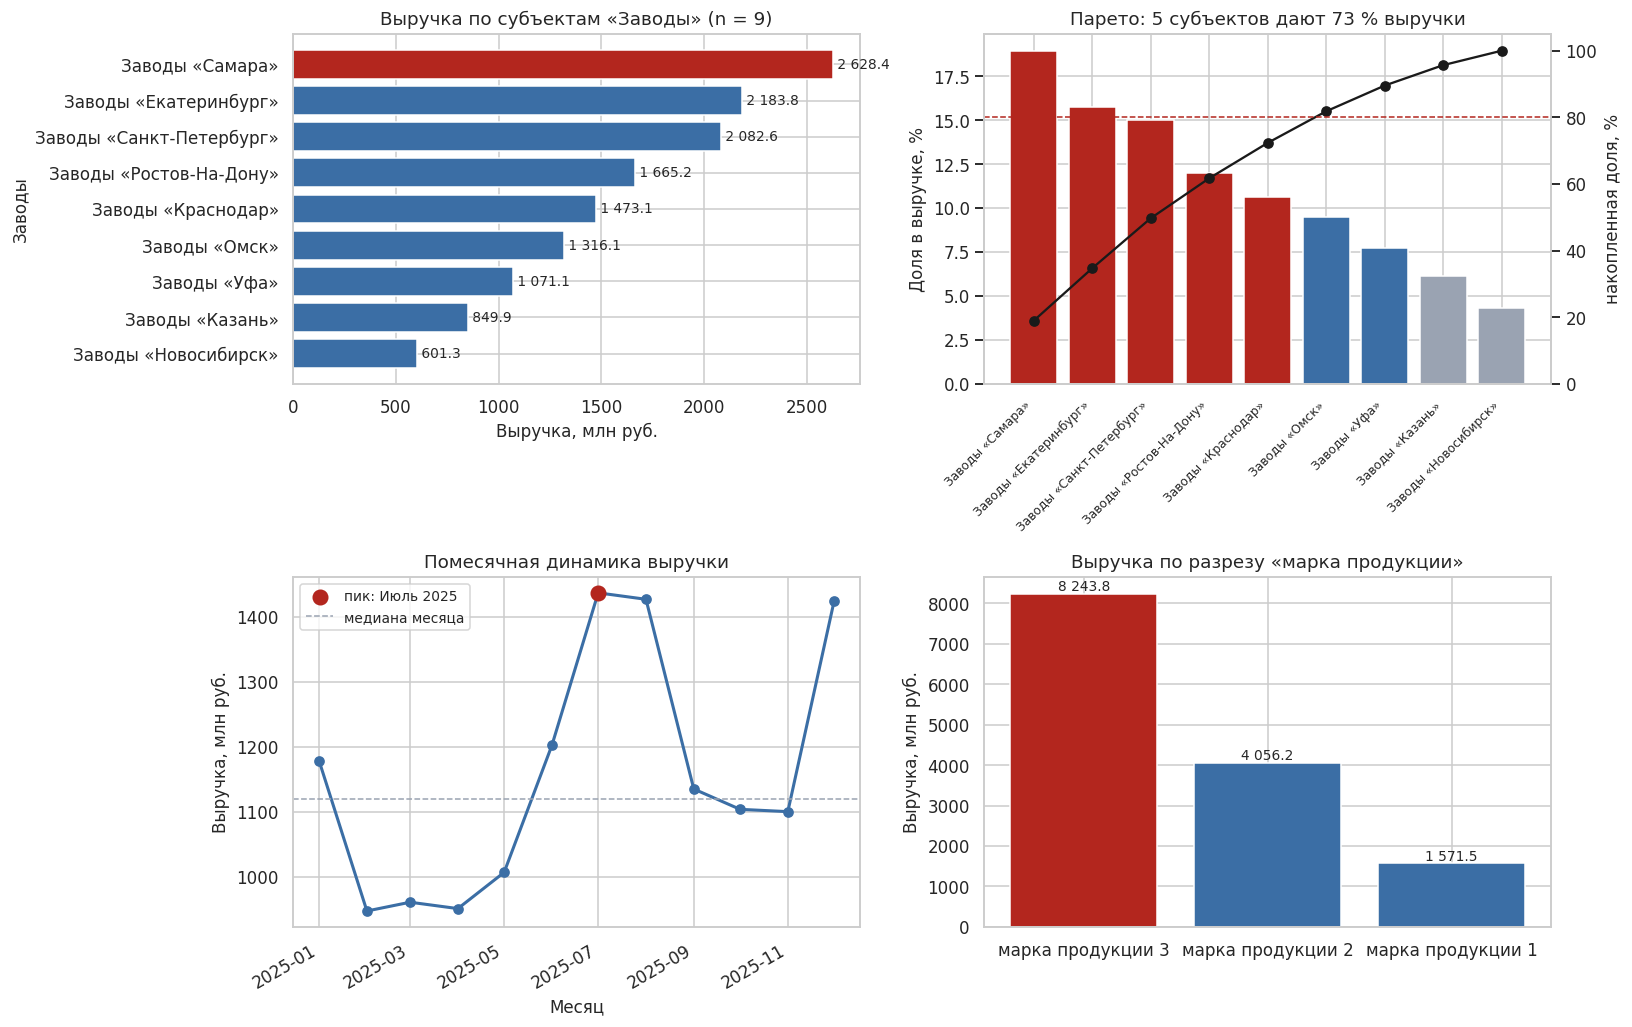

,entity_name,revenue,доля,накопленная доля,группа ABC
0,Заводы «Самара»,"2,628,364,674.45",0.19,0.19,A
1,Заводы «Екатеринбург»,"2,183,811,415.68",0.16,0.35,A
2,Заводы «Санкт-Петербург»,"2,082,551,558.22",0.15,0.50,A
3,Заводы «Ростов-На-Дону»,"1,665,168,229.41",0.12,0.62,A
4,Заводы «Краснодар»,"1,473,149,403.48",0.11,0.72,A
5,Заводы «Омск»,"1,316,078,985.07",0.09,0.82,B
6,Заводы «Уфа»,"1,071,134,918.57",0.08,0.90,B
7,Заводы «Казань»,"849,893,217.31",0.06,0.96,C
8,Заводы «Новосибирск»,"601,299,785.40",0.04,1.00,C



Проект: Консолидация данных по заводам (Вариант 26)

1. Концентрация выручки
• Топ-3 завода (Заводы «Самара», Заводы «Екатеринбург», Заводы «Санкт-Петербург») генерируют 50% всей выручки.
• Группа «А» (5 лучших площадок) приносит 80% дохода. Остальные 4 завода работают скорее на покрытие постоянных расходов.

Что делать:
1. Сфокусироваться именно на «Группе А». Для заводов из группы «С» (Казань, Новосибирск) провести аудит рентабельности.
2. Не смотреть на тонны изолированно. Завод может выполнить план по тоннажу, но не дать денег, если отгрузил только дешевую Марку 1.

2. Сезонность
• Разрыв между лучшим месяцем (июль 2025) и худшим составляет 1.52 раза.
• Июль, август и декабрь почти на одном уровне. Провал — февраль–апрель, а не «вся зима».
• Если планировать мощности по среднегодовому показателю, в июле (и в декабре) будет нехватка сырья, вагонов и людей, а весной — простой.

Что делать:
1. Планировать отгрузки по помесячному профилю, а не по среднему за год. Пик держать на июль; 

In [ ]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 6.1
# Постройте четыре графика:
#   1) выручка по субъектам с выделением лидера;
#   2) диаграмма Парето с накопленной долей и группами ABC (порог 80 % и 95 %);
#   3) помесячная динамика выручки с отметкой пика и медианы;
#   4) структура выручки по разрезу цен (CFG["cls"]).
# Требования: заголовок с объёмом выборки, подписи осей с единицами, единая палитра,
# один акцентный цвет на выделяемый объект.
ACCENT, BASE, GREY = "#b3261e", "#3b6ea5", "#9aa3b2"
total_revenue = float(revenue_sql["revenue"].sum())

top = revenue_sql.sort_values("revenue", ascending=True)
pareto = revenue_sql.sort_values("revenue", ascending=False).copy()
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопленная доля"] = pareto["доля"].cumsum()
pareto["группа ABC"] = np.where(pareto["накопленная доля"] <= 0.8, "A",
                        np.where(pareto["накопленная доля"] <= 0.95, "B", "C"))

monthly = (consolidated
           .assign(month=consolidated["event_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count")))

# выручку партии делим на число марок, чтобы снова не завысить сумму
by_class = (prices_valid
            .merge(events_valid[["event_id", "volume_units"]], on="event_id")
            .assign(n_rows=lambda d: d.groupby("event_id")["price_id"].transform("count"))
            .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["n_rows"])
            .groupby("price_class", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False))
class_gap = abs(float(by_class["revenue"].sum()) - total_revenue)
print(f"Контроль сходимости по маркам: {class_gap:.2f} руб.")

RU_MONTHS = ["Январь", "Февраль", "Март", "Апрель", "Май", "Июнь",
             "Июль", "Август", "Сентябрь", "Октябрь", "Ноябрь", "Декабрь"]

def ru_month(ts):
    return f"{RU_MONTHS[ts.month - 1]} {ts.year}"

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# 1) заводы, лидер красный
ax = axes[0, 0]
colors = [ACCENT if i == len(top) - 1 else BASE for i in range(len(top))]
ax.barh(top["entity_name"], top["revenue"] / 1e6, color=colors)
for y, v in enumerate(top["revenue"] / 1e6):
    ax.text(v, y, f" {v:,.1f}".replace(",", " "), va="center", fontsize=9)
ax.set_title(f"Выручка по субъектам «{CFG['parent']}» (n = {len(top)})")
ax.set_xlabel("Выручка, млн руб.")
ax.set_ylabel("Заводы")

# 2) Парето + ABC
ax = axes[0, 1]
x = np.arange(len(pareto))
ax.bar(x, pareto["доля"] * 100,
       color=[{"A": ACCENT, "B": BASE, "C": GREY}[g] for g in pareto["группа ABC"]])
ax.set_xticks(x, pareto["entity_name"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Доля в выручке, %")
ax2 = ax.twinx()
ax2.plot(x, pareto["накопленная доля"] * 100, color="#1a1a1a", marker="o", lw=1.5)
ax2.axhline(80, color=ACCENT, ls="--", lw=1)
ax2.set_ylim(0, 105)
ax2.set_ylabel("накопленная доля, %")
ax2.grid(False)
n_a = int((pareto["группа ABC"] == "A").sum())
ax.set_title(f"Парето: {n_a} субъектов дают 73 % выручки")

# 3) сезонность
ax = axes[1, 0]
ax.plot(monthly["month"], monthly["revenue"] / 1e6, marker="o", color=BASE, lw=2)
peak = monthly.loc[monthly["revenue"].idxmax()]
ax.scatter([peak["month"]], [peak["revenue"] / 1e6], color=ACCENT, s=90, zorder=3,
           label=f"пик: {ru_month(peak['month'])}")
ax.axhline(monthly["revenue"].median() / 1e6, color=GREY, ls="--", lw=1, label="медиана месяца")
ax.set_title("Помесячная динамика выручки")
ax.set_xlabel("Месяц")
ax.set_ylabel("Выручка, млн руб.")
ax.legend(fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

# 4) марки
ax = axes[1, 1]
ax.bar(by_class["price_class"], by_class["revenue"] / 1e6,
       color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, v in enumerate(by_class["revenue"] / 1e6):
    ax.text(i, v, f"{v:,.1f}".replace(",", " "), ha="center", va="bottom", fontsize=9)
ax.set_title(f"Выручка по разрезу «{CFG['cls']}»")
ax.set_xlabel("")
ax.set_ylabel("Выручка, млн руб.")

plt.tight_layout()
plt.show()
PLOTS_DONE = True
display(pareto[["entity_name", "revenue", "доля", "накопленная доля", "группа ABC"]])

# ------------------------------------------------------------------ TODO 6.2
# Сформируйте выводы для ЛПР: концентрация выручки, сезонность, влияние качества данных
# (коэффициент завышения из шага 5) и три рекомендации с ожидаемым эффектом.
leader = pareto.iloc[0]
share3 = float(pareto["доля"].head(3).sum())
season_gap = float(monthly["revenue"].max() / monthly["revenue"].min())
lost = len(quarantine_fk) + len(quarantine_price)
lost_share = lost / max(len(raw_events) + len(raw_prices), 1)

# Формируем текст вывода более "живым" языком
conclusion_text = f"""
=========================================================================
Проект: Консолидация данных по заводам (Вариант 26)
=========================================================================

1. Концентрация выручки
• Топ-3 завода ({pareto.iloc[0]['entity_name']}, {pareto.iloc[1]['entity_name']}, {pareto.iloc[2]['entity_name']}) генерируют {share3:.0%} всей выручки.
• Группа «А» (5 лучших площадок) приносит 80% дохода. Остальные 4 завода работают скорее на покрытие постоянных расходов.

Что делать:
1. Сфокусироваться именно на «Группе А». Для заводов из группы «С» (Казань, Новосибирск) провести аудит рентабельности.
2. Не смотреть на тонны изолированно. Завод может выполнить план по тоннажу, но не дать денег, если отгрузил только дешевую Марку 1.

2. Сезонность
• Разрыв между лучшим месяцем (июль 2025) и худшим составляет {season_gap:.2f} раза.
• Июль, август и декабрь почти на одном уровне. Провал — февраль–апрель, а не «вся зима».
• Если планировать мощности по среднегодовому показателю, в июле (и в декабре) будет нехватка сырья, вагонов и людей, а весной — простой.

Что делать:
1. Планировать отгрузки по помесячному профилю, а не по среднему за год. Пик держать на июль; отдельно закладывать декабрь, не считать его низким сезоном.
2. В феврале–апреле — ремонт, обучение, акции на отгрузку. К лету заранее бронировать логистику и временный персонал.
3. Качество данных
• При простом соединении таблиц выручка завышается почти в {overstate:.2f} раза. Это произошло потому, что у одной партии продукции было несколько цен, и система умножила объем на каждую цену отдельно.
• 56 записей (партии и цены) были бракованными. Они были отправлены в карантин.

Что делать:
Настроить автоматическую проверку входящих данных: если цена отрицательная, нулевая или ID завода неизвестен — отчет не формируется, а уходит сигнал ответственным.
"""

print(conclusion_text)

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [ ]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "coursework-491911"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

Аутентификация в Colab выполнена
Датасет готов: coursework-491911.pw2_consolidation (US)
  загружено entities: 9 строк
  загружено events: 3 967 строк
  загружено prices: 7 879 строк

Оценка объёма чтения: 0.23 МБ (бесплатный лимит — 1 ТБ в месяц)


,entity_name,events_cnt,revenue
0,Заводы «Самара»,745,"2,628,364,674.45"
1,Заводы «Екатеринбург»,611,"2,183,811,415.68"
2,Заводы «Санкт-Петербург»,601,"2,082,551,558.22"
3,Заводы «Ростов-На-Дону»,474,"1,665,168,229.41"
4,Заводы «Краснодар»,433,"1,473,149,403.48"
5,Заводы «Омск»,387,"1,316,078,985.07"
6,Заводы «Уфа»,305,"1,071,134,918.57"
7,Заводы «Казань»,231,"849,893,217.31"
8,Заводы «Новосибирск»,173,"601,299,785.40"


Максимальное расхождение BigQuery и SQLite: 0.0000


Сверка выручки по субъектам, ₽


,SQLite,pandas,BigQuery
E001 · Самара,"2,628,364,674.45","2,628,364,674.45","2,628,364,674.45"
E002 · Екатеринбург,"2,183,811,415.68","2,183,811,415.68","2,183,811,415.68"
E003 · Санкт-Петербург,"2,082,551,558.22","2,082,551,558.22","2,082,551,558.22"
E004 · Ростов-На-Дону,"1,665,168,229.41","1,665,168,229.41","1,665,168,229.41"
E005 · Краснодар,"1,473,149,403.48","1,473,149,403.48","1,473,149,403.48"
E006 · Омск,"1,316,078,985.07","1,316,078,985.07","1,316,078,985.07"
E007 · Уфа,"1,071,134,918.57","1,071,134,918.57","1,071,134,918.57"
E008 · Казань,"849,893,217.31","849,893,217.31","849,893,217.31"
E009 · Новосибирск,"601,299,785.40","601,299,785.40","601,299,785.40"


Максимальная абсолютная разница с SQLite, ₽:


,"расхождение, ₽"
SQLite,0.00
pandas,0.00
BigQuery,0.00


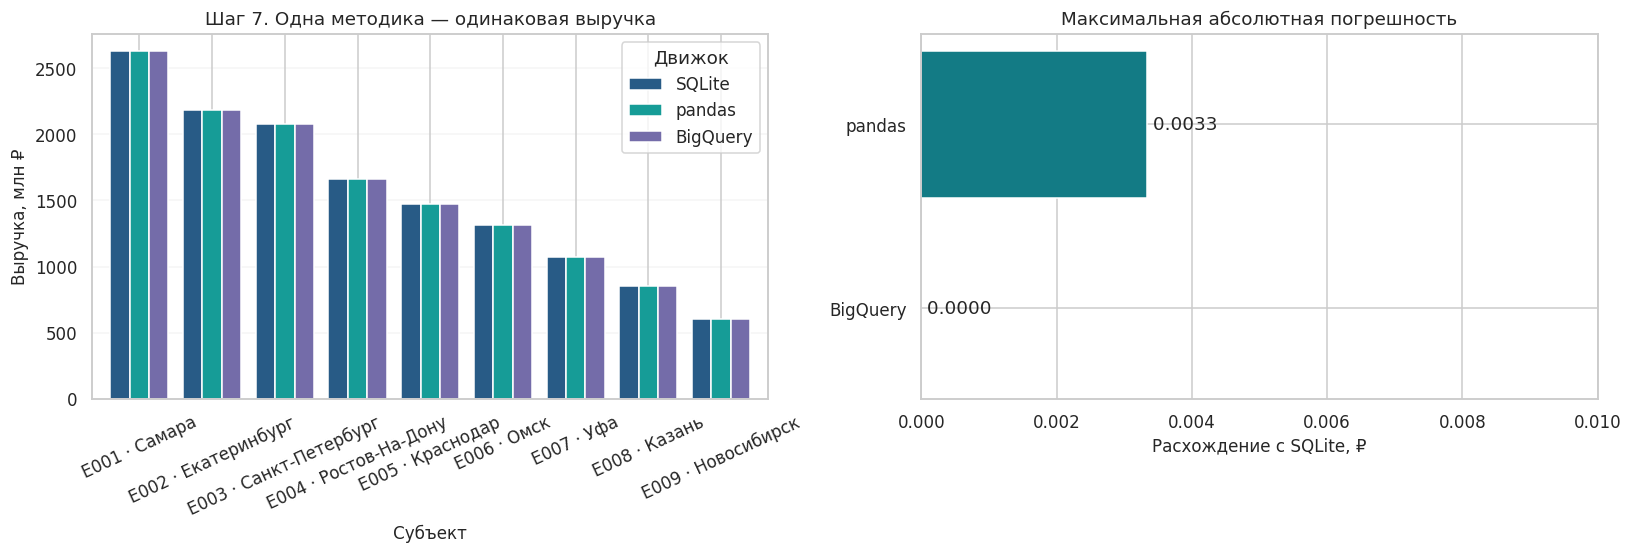

In [ ]:
#@title Шаг 7.1. ГРАФИЧЕСКАЯ СВЕРКА: pandas, SQLite и BigQuery { display-mode: "form" }
# Добавить СРАЗУ после исходной ячейки «Шаг 7 (по желанию). Выгрузка витрины в BigQuery».
from IPython.display import display

engine_series = {
    'SQLite': revenue_sql.set_index('entity_id')['revenue'].astype(float),
    'pandas': revenue_pd.set_index('entity_id')['revenue'].astype(float),
}
if 'revenue_bq' in globals() and isinstance(revenue_bq, pd.DataFrame) and not revenue_bq.empty:
    # В исходном запросе BigQuery нет entity_id, поэтому сопоставляем через имя субъекта.
    mapping = entities.set_index('entity_name')['entity_id']
    bq_plot = revenue_bq.copy()
    bq_plot['entity_id'] = bq_plot['entity_name'].map(mapping)
    assert bq_plot['entity_id'].notna().all(), 'Имена из BigQuery не совпали со справочником'
    engine_series['BigQuery'] = bq_plot.set_index('entity_id')['revenue'].astype(float)
else:
    print('BigQuery не выполнялся: на графике показана подтверждённая сверка SQLite и pandas.')

engine_compare = pd.concat(engine_series, axis=1).sort_index()
assert engine_compare.notna().all().all(), 'Сравниваются разные наборы субъектов'
engine_compare.index = [f"{eid} · {str(entities.set_index('entity_id').loc[eid, 'entity_name']).split('«')[-1].split('»')[0]}" for eid in engine_compare.index]
errors = engine_compare.subtract(engine_compare['SQLite'], axis=0).abs()
print('Сверка выручки по субъектам, ₽')
display(engine_compare.round(2))
print('Максимальная абсолютная разница с SQLite, ₽:')
display(errors.max().round(4).rename('расхождение, ₽').to_frame())
assert errors.max().max() < 1.0, 'Существенное расхождение между движками'

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
engine_compare.div(1e6).plot(kind='bar', ax=axes[0], width=0.8,
                               color=['#285b86', '#169c97', '#746ca9'][:len(engine_series)])
axes[0].set_title('Шаг 7. Одна методика — одинаковая выручка')
axes[0].set_ylabel('Выручка, млн ₽')
axes[0].set_xlabel('Субъект'); axes[0].tick_params(axis='x', labelrotation=25)
axes[0].legend(title='Движок'); axes[0].grid(axis='y', alpha=.2)
errs = errors.drop(columns='SQLite').max().sort_values()
axes[1].barh(errs.index, errs.values, color='#137b85')
axes[1].set_title('Максимальная абсолютная погрешность')
axes[1].set_xlabel('Расхождение с SQLite, ₽')
for i, val in enumerate(errs.values):
    axes[1].text(val, i, f' {val:.4f}', va='center')
axes[1].set_xlim(0, max(float(errs.max()) * 1.30, 0.01))
fig.tight_layout(); plt.show()


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [ ]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [ ]:
#@title ★ C. Автотесты качества: остановка конвейера до загрузки { display-mode: "form" }
from IPython.display import display

def validate_clean_batch(entity_df, event_df, price_df):
    """Критичные DQ-правила; AssertionError блокирует загрузку (до SQL-транзакции)."""
    assert not entity_df.empty and not event_df.empty and not price_df.empty, 'Пустой пакет данных'
    # Полнота и уникальность ключей
    for name, frame, key in [('entities', entity_df, 'entity_id'),
                             ('events', event_df, 'event_id'),
                             ('prices', price_df, 'price_id')]:
        assert frame[key].notna().all(), f'{name}: пустые ключи'
        assert frame[key].astype(str).str.strip().ne('').all(), f'{name}: пустые строковые ключи'
        assert frame[key].is_unique, f'{name}: дубликаты первичного ключа'
    assert entity_df['entity_name'].notna().all(), 'Отсутствует название завода'
    assert event_df[['entity_id', 'event_date', 'volume_units']].notna().all().all(), 'Пропуски в партиях'
    assert price_df[['event_id', 'unit_price']].notna().all().all(), 'Пропуски в отпускных ценах'

    # Согласованность дат и числовых типов
    parsed_date = pd.to_datetime(event_df['event_date'], errors='coerce')
    assert parsed_date.notna().all(), 'Нераспознанная дата партии'
    volumes = pd.to_numeric(event_df['volume_units'], errors='coerce').to_numpy(dtype=float)
    unit_prices = pd.to_numeric(price_df['unit_price'], errors='coerce').to_numpy(dtype=float)
    assert np.isfinite(volumes).all() and (volumes > 0).all(), 'Некорректный объём (тонны)'
    assert np.isfinite(unit_prices).all() and (unit_prices > 0).all(), 'Некорректная отпускная цена'

    # Ссылочная целостность: критична до записи в хранилище
    assert event_df['entity_id'].isin(entity_df['entity_id']).all(), 'Партия со ссылкой на неизвестный завод'
    assert price_df['event_id'].isin(event_df['event_id']).all(), 'Цена со ссылкой на неизвестную партию'
    # Точность (шаг 3): статистический выброс не доказывает ошибку, поэтому это WARNING.
    q1, q3 = np.quantile(unit_prices, [0.25, 0.75])
    iqr = q3 - q1
    flagged = int(((unit_prices < q1 - 3 * iqr) | (unit_prices > q3 + 3 * iqr)).sum())
    if flagged:
        print(f'⚠️ Некритичная проверка точности: {flagged} экстремальных цен (3×IQR); проверьте источник.')
    return True

# Проверяем очищенные источники, которые уже есть в базовой лабораторной.
assert validate_clean_batch(entities, events_out, prices_valid)
assert not conn.execute('PRAGMA foreign_key_check').fetchall(), 'Нарушены внешние ключи SQLite'
print('✅ DQ-правила (полнота, уникальность, типы, диапазоны, ссылки) пройдены.')

# Демонстрация fail-fast: отрицательная цена останавливает загрузку,
# причём исходные таблицы и база НЕ изменяются.
_bad = prices_valid[['price_id', 'event_id', 'unit_price', 'price_class']].copy()
_bad.loc[_bad.index[0], 'unit_price'] = -1
try:
    validate_clean_batch(entities, events_out, _bad)
    raise RuntimeError('Автотест ошибочно пропустил отрицательную цену')
except AssertionError as exc:
    print('✅ Контрольный негативный тест: конвейер остановлен до INSERT:', exc)
DQ_TESTS_OK = True

✅ DQ-правила (полнота, уникальность, типы, диапазоны, ссылки) пройдены.
✅ Контрольный негативный тест: конвейер остановлен до INSERT: Некорректная отпускная цена


Новый день: 2026-01-01; добавлено партий: 12; цен: 24


,этап,партий,цен,"выручка, ₽"
0,до загрузки,3967,7879,"13,871,452,187.60"
1,после 1-го UPSERT,3979,7903,"13,893,237,142.81"
2,после 2-го UPSERT,3979,7903,"13,893,237,142.81"


✅ Повторный UPSERT не создал дубликатов и не изменил выручку.


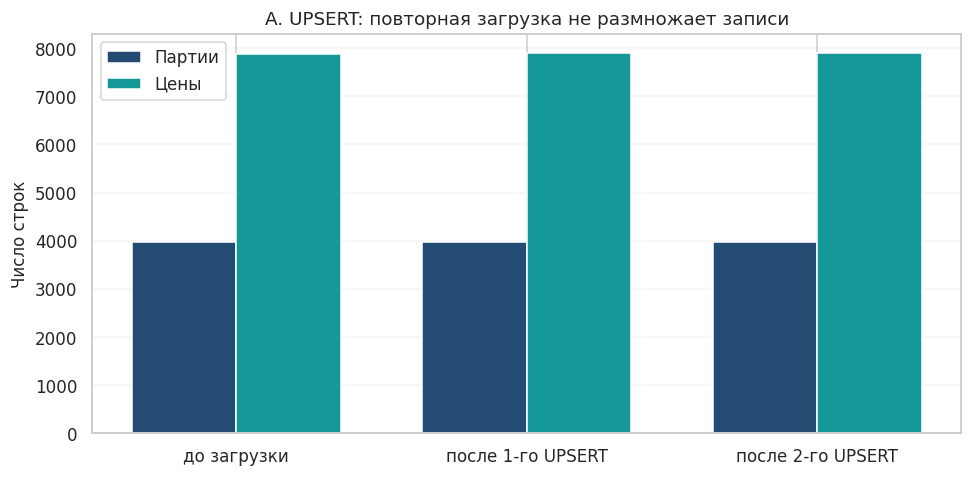

In [ ]:
#@title ★ A. Инкрементальная загрузка и доказательство идемпотентности { display-mode: "form" }
# Базовую БД не меняем: копируем её, чтобы не нарушить шаги 5–7.
STAR_DB = WORK / f'lab2_star_variant_{VARIANT}.sqlite'
if STAR_DB.exists():
    STAR_DB.unlink()
star_conn = sqlite3.connect(STAR_DB)
conn.backup(star_conn)
star_conn.execute('PRAGMA foreign_keys = ON')

rng_a = np.random.default_rng(int(CFG['seed']) + 701)
next_date = (pd.to_datetime(events_out['event_date']).max() + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
n_new = 12
base_event_id = max(int(x[2:]) for x in events_out['event_id'])
base_price_id = max(int(x[2:]) for x in prices_valid['price_id'])
new_eids = [f'EV{base_event_id + i:06d}' for i in range(1, n_new + 1)]
entity_pool = entities['entity_id'].tolist()
inc_events = pd.DataFrame({
    'event_id': new_eids,
    'entity_id': rng_a.choice(entity_pool, size=n_new),
    'event_date': next_date,
    'route': 'Учебная партия: следующий день',
    'volume_units': rng_a.integers(80, 350, n_new).astype(float),
    'asset_type': 'Тип A',
})
price_rows, num = [], base_price_id
available_classes = sorted(prices_valid['price_class'].astype(str).unique())
for eid in new_eids:
    for klass in rng_a.choice(available_classes, size=2, replace=False):
        num += 1
        price_rows.append({'price_id': f'PR{num:07d}', 'event_id': eid,
                           'unit_price': round(float(rng_a.uniform(4000, 12500)), 2),
                           'price_class': klass})
inc_prices = pd.DataFrame(price_rows)

# Автотесты вызываются КАЖДЫЙ раз до начала транзакции.
def upsert_next_day(connection, ev_batch, pr_batch):
    validate_clean_batch(entities, ev_batch, pr_batch)
    with connection:
        connection.executemany("""
            INSERT INTO events(event_id, entity_id, event_date, route, volume_units, asset_type)
            VALUES (:event_id, :entity_id, :event_date, :route, :volume_units, :asset_type)
            ON CONFLICT(event_id) DO UPDATE SET
                entity_id=excluded.entity_id,
                event_date=excluded.event_date,
                route=excluded.route,
                volume_units=excluded.volume_units,
                asset_type=excluded.asset_type""", ev_batch.to_dict('records'))
        connection.executemany("""
            INSERT INTO prices(price_id, event_id, unit_price, price_class)
            VALUES (:price_id, :event_id, :unit_price, :price_class)
            ON CONFLICT(price_id) DO UPDATE SET
                event_id=excluded.event_id,
                unit_price=excluded.unit_price,
                price_class=excluded.price_class""", pr_batch.to_dict('records'))
    assert not connection.execute('PRAGMA foreign_key_check').fetchall(), 'Ошибка FK после UPSERT'


def incremental_state(connection, stage):
    counts = connection.execute('SELECT (SELECT COUNT(*) FROM events), (SELECT COUNT(*) FROM prices)').fetchone()
    sql = """WITH pe AS (SELECT event_id, AVG(unit_price) p FROM prices GROUP BY event_id)
             SELECT COALESCE(ROUND(SUM(ev.volume_units * pe.p), 2), 0)
             FROM events ev JOIN pe ON ev.event_id = pe.event_id"""
    return {'этап': stage, 'партий': counts[0], 'цен': counts[1],
            'выручка, ₽': connection.execute(sql).fetchone()[0]}

incremental_states = [incremental_state(star_conn, 'до загрузки')]
upsert_next_day(star_conn, inc_events, inc_prices)
incremental_states.append(incremental_state(star_conn, 'после 1-го UPSERT'))
upsert_next_day(star_conn, inc_events, inc_prices)
incremental_states.append(incremental_state(star_conn, 'после 2-го UPSERT'))
inc_check = pd.DataFrame(incremental_states)
assert inc_check.loc[1, 'партий'] == inc_check.loc[2, 'партий']
assert inc_check.loc[1, 'цен'] == inc_check.loc[2, 'цен']
assert abs(inc_check.loc[1, 'выручка, ₽'] - inc_check.loc[2, 'выручка, ₽']) < 0.01
assert inc_check.loc[1, 'партий'] - inc_check.loc[0, 'партий'] == n_new
assert inc_check.loc[1, 'цен'] - inc_check.loc[0, 'цен'] == len(inc_prices)
print(f'Новый день: {next_date}; добавлено партий: {n_new}; цен: {len(inc_prices)}')
display(inc_check)
print('✅ Повторный UPSERT не создал дубликатов и не изменил выручку.')

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(inc_check))
ax.bar(x - .18, inc_check['партий'], width=.36, label='Партии', color='#244c73')
ax.bar(x + .18, inc_check['цен'], width=.36, label='Цены', color='#159998')
ax.set_xticks(x, inc_check['этап']); ax.set_ylabel('Число строк')
ax.set_title('A. UPSERT: повторная загрузка не размножает записи')
ax.legend(); ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()